# Loan approval prediction: what actually drives the decision?
**614 loan applications, tested with repeated cross-validation and a protected-attribute check**

**Summary.** A logistic regression approves/rejects with about **81% accuracy** against a 68.7% "approve everyone" baseline. But almost all of that comes from **one variable, credit history**: a rule that uses nothing else scores the same 80.9%. Adding income, loan amount, property area and the rest lifts the ranking quality (ROC AUC 0.705 to about 0.75) without changing accuracy. Gender and marital status add nothing and are left out of the final model, which is the right design for a lending decision.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.25})
FIG=Path('../figures'); RES=Path('../results'); FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
df=pd.read_csv('../data/loan_applications.csv'); df['approved']=(df.Loan_Status=='Y').astype(int)
print(df.shape, '| duplicate IDs:',int(df.Loan_ID.duplicated().sum()), '| approval rate:',round(df.approved.mean(),3))
miss=df.isna().sum(); miss[miss>0].to_frame('missing values')

(614, 14) | duplicate IDs: 0 | approval rate: 0.687


,missing values
Gender,13
Married,3
Dependents,15
Self_Employed,32
LoanAmount,22
Loan_Amount_Term,14
Credit_History,50


## 1. Data and missing values
614 applicants, 12 inputs plus the outcome. Seven columns have missing values (credit history 50, self-employed 32, loan amount 22, dependents 15, loan term 14, gender 13, married 3). I do not drop those rows: imputation (median for numbers, most common value for categories) happens **inside** each cross-validation fold, so no information from the test fold leaks into the fill-in values.

The original version scaled and imputed before splitting. Doing it inside the pipeline is the safe pattern.

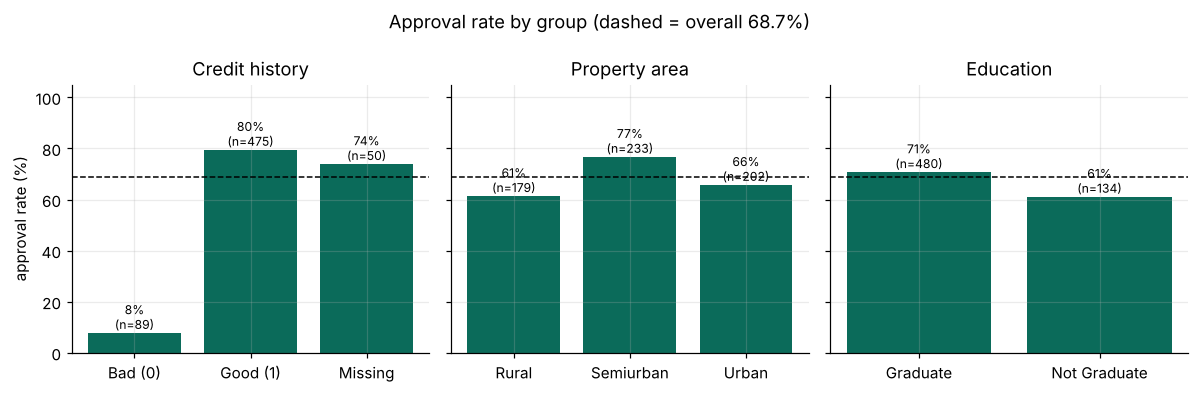

In [2]:
fig,axs=plt.subplots(1,3,figsize=(11,3.6),sharey=True)
ch=df.assign(Credit_History=df.Credit_History.map({0.0:'Bad (0)',1.0:'Good (1)'}).fillna('Missing'))
for ax,col,title in zip(axs,[ch['Credit_History'],df['Property_Area'],df['Education']],['Credit history','Property area','Education']):
    g=df.groupby(col).approved.agg(['mean','size']); ax.bar(g.index,g['mean']*100,color='#0b6b5a'); ax.set_title(title)
    for i,(m,n) in enumerate(zip(g['mean'],g['size'])): ax.text(i,m*100+1.5,f'{m*100:.0f}%\n(n={n})',ha='center',fontsize=8)
    ax.axhline(df.approved.mean()*100,color='k',ls='--',lw=1); ax.set_ylim(0,105)
axs[0].set_ylabel('approval rate (%)'); fig.suptitle('Approval rate by group (dashed = overall 68.7%)'); fig.tight_layout(); fig.savefig(FIG/'01_approval_rates.png'); plt.show()

## 2. What the raw data says
Credit history dominates: **80% of applicants with a good credit history are approved, versus 8% of those with a bad one**. Applicants with missing history look like good-history applicants (74%). Property area and education matter far less.

In [3]:
CAT=['Gender','Married','Dependents','Education','Self_Employed','Property_Area','Credit_History']
NUM=['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term']
def pipe(model,cats,nums):
    steps=[]
    if cats: steps.append(('c',Pipeline([('i',SimpleImputer(strategy='most_frequent')),('o',OneHotEncoder(handle_unknown='ignore'))]),cats))
    if nums: steps.append(('n',Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler())]),nums))
    return Pipeline([('p',ColumnTransformer(steps)),('m',model)])
MODELS={'Logistic regression':lambda:LogisticRegression(max_iter=2000),
        'Random forest':lambda:RandomForestClassifier(300,min_samples_leaf=5,random_state=0,n_jobs=-1),
        'Gradient boosting':lambda:HistGradientBoostingClassifier(max_depth=3,learning_rate=.05,max_iter=100,random_state=0)}
SETS={'Credit history only':(['Credit_History'],[]),
      'All except gender & marital status':([c for c in CAT if c not in ('Gender','Married')],NUM),
      'All features':(CAT,NUM)}
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=5,random_state=0); y=df.approved; rows=[]
for sn,(cc,nn) in SETS.items():
    for mn,mk in MODELS.items():
        r=cross_validate(pipe(mk(),cc,nn),df[cc+nn],y,cv=cv,scoring=['accuracy','balanced_accuracy','roc_auc'])
        rows.append({'features':sn,'model':mn,'accuracy':r['test_accuracy'].mean(),'accuracy sd':r['test_accuracy'].std(),
                     'balanced accuracy':r['test_balanced_accuracy'].mean(),'ROC AUC':r['test_roc_auc'].mean()})
R=pd.DataFrame(rows); R.round(3).to_csv(RES/'model_comparison.csv',index=False)
print('Majority-class baseline accuracy:',round(max(y.mean(),1-y.mean()),3),'(5-fold x 5 repeats = 25 test folds per cell)')
R.round(3)

Majority-class baseline accuracy: 0.687 (5-fold x 5 repeats = 25 test folds per cell)


,features,model,accuracy,accuracy sd,balanced accuracy,ROC AUC
0,Credit history only,Logistic regression,0.809,0.019,0.705,0.705
1,Credit history only,Random forest,0.809,0.019,0.705,0.705
2,Credit history only,Gradient boosting,0.809,0.019,0.705,0.705
3,All except gender & marital status,Logistic regression,0.810,0.022,0.707,0.748
4,All except gender & marital status,Random forest,0.808,0.019,0.705,0.760
5,All except gender & marital status,Gradient boosting,0.807,0.021,0.705,0.744
6,All features,Logistic regression,0.810,0.022,0.707,0.755
7,All features,Random forest,0.809,0.019,0.705,0.757
8,All features,Gradient boosting,0.807,0.019,0.706,0.741


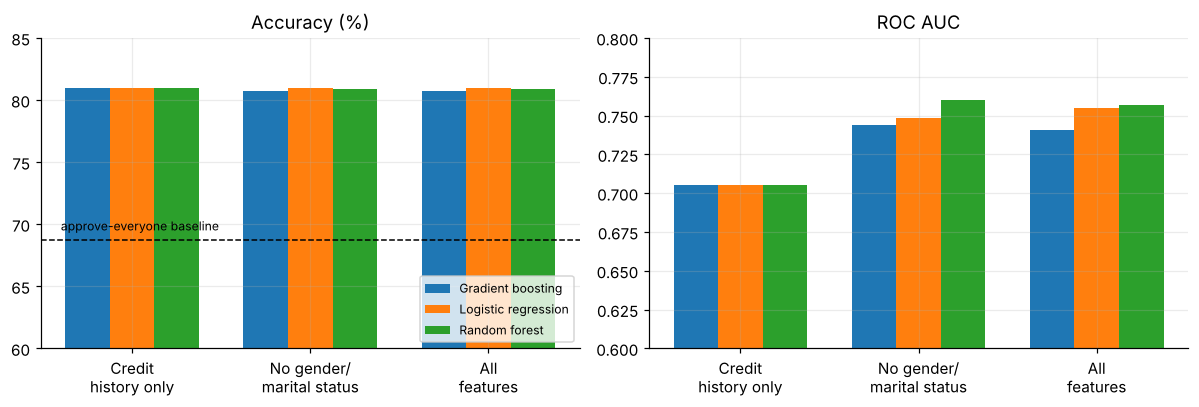

In [4]:
P=R.pivot(index='features',columns='model',values='accuracy').loc[list(SETS)]
A=R.pivot(index='features',columns='model',values='ROC AUC').loc[list(SETS)]
fig,axs=plt.subplots(1,2,figsize=(11,3.8)); w=.25; xs=np.arange(len(P))
for i,m in enumerate(P.columns):
    axs[0].bar(xs+(i-1)*w,P[m]*100,w,label=m); axs[1].bar(xs+(i-1)*w,A[m],w,label=m)
axs[0].axhline(68.7,color='k',ls='--',lw=1); axs[0].text(-.4,69.5,'approve-everyone baseline',fontsize=8)
axs[0].set_ylim(60,85); axs[0].set_title('Accuracy (%)'); axs[1].set_ylim(.6,.8); axs[1].set_title('ROC AUC')
for a in axs: a.set_xticks(xs); a.set_xticklabels(['Credit\nhistory only','No gender/\nmarital status','All\nfeatures'])
axs[0].legend(fontsize=8,loc='lower right'); fig.tight_layout(); fig.savefig(FIG/'02_model_comparison.png'); plt.show()

## 3. Results
- **Accuracy is flat at about 81%** whatever the model and whatever the features. The credit-history-only rule already gets 80.9%.
- **The extra features improve ranking, not accuracy**: AUC rises from 0.705 to roughly 0.75, meaning the model orders applicants better but with a 0.5 cut-off it still approves and rejects the same people.
- **A simple logistic regression does as well as random forest and boosting.** On 614 rows with mostly categorical inputs, there is nothing for the complex models to find.
- **Gender and marital status add nothing** (accuracy and AUC are the same with or without them), so excluding them costs no predictive power.

Cross-validated standard deviations are about 2 percentage points, so differences between models of less than one point are noise.

In [5]:
# Final design: logistic regression without gender and marital status. Out-of-fold predictions for error analysis.
cc,nn=SETS['All except gender & marital status']; X=df[cc+nn]
oof=cross_val_predict(pipe(LogisticRegression(max_iter=2000),cc,nn),X,y,cv=StratifiedKFold(5,shuffle=True,random_state=0),method='predict_proba')[:,1]
pred=(oof>=.5).astype(int)
cm=confusion_matrix(y,pred); print('accuracy %.3f | balanced accuracy %.3f | AUC %.3f'%(accuracy_score(y,pred),balanced_accuracy_score(y,pred),roc_auc_score(y,oof)))
print(pd.DataFrame(cm,index=['actual rejected','actual approved'],columns=['predicted rejected','predicted approved']))
print('rejected applicants correctly caught: %.0f%%   approved applicants correctly approved: %.0f%%'%(cm[0,0]/cm[0].sum()*100,cm[1,1]/cm[1].sum()*100))

accuracy 0.813 | balanced accuracy 0.710 | AUC 0.748
                 predicted rejected  predicted approved
actual rejected                  84                 108
actual approved                   7                 415
rejected applicants correctly caught: 44%   approved applicants correctly approved: 98%


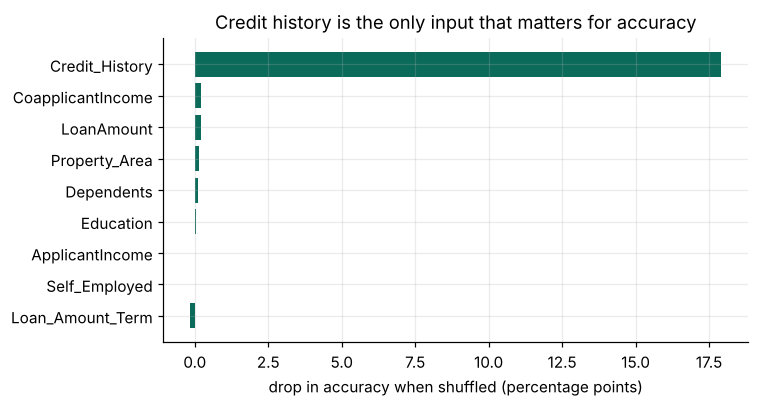

,importance
Credit_History,0.1792
CoapplicantIncome,0.0021
LoanAmount,0.0020
Property_Area,0.0015
Dependents,0.0011


In [6]:
# Which inputs matter? Permutation importance on held-out folds (drop in accuracy when a column is shuffled).
imp=pd.DataFrame(0.0,index=cc+nn,columns=['importance'])
for tr,te in StratifiedKFold(5,shuffle=True,random_state=1).split(X,y):
    m=pipe(LogisticRegression(max_iter=2000),cc,nn).fit(X.iloc[tr],y.iloc[tr])
    pi=permutation_importance(m,X.iloc[te],y.iloc[te],scoring='accuracy',n_repeats=20,random_state=0)
    imp['importance']+=pi.importances_mean/5
imp=imp.sort_values('importance'); imp.round(4).sort_values('importance',ascending=False).to_csv(RES/'permutation_importance.csv')
fig,ax=plt.subplots(figsize=(7,3.8)); ax.barh(imp.index,imp.importance*100,color='#0b6b5a'); ax.set_xlabel('drop in accuracy when shuffled (percentage points)')
ax.set_title('Credit history is the only input that matters for accuracy'); fig.tight_layout(); fig.savefig(FIG/'03_importance.png'); plt.show()
imp.sort_values('importance',ascending=False).round(4).head(5)

## 4. Fairness check
Gender and marital status are excluded from the final model, but the data still contain differences. Comparing actual approval rates with the model's predicted approval rates (out-of-fold) shows whether the model reproduces them through other variables such as co-applicant income.

In [7]:
chk=[]
for col in ['Gender','Married']:
    g=df.assign(pred=pred).groupby(col).agg(n=('approved','size'),actual_approval=('approved','mean'),model_approval=('pred','mean'))
    g.insert(0,'attribute',col); chk.append(g.reset_index().rename(columns={col:'group'}))
F=pd.concat(chk); F.round(3).to_csv(RES/'group_rates.csv',index=False); F.round(3)

,group,attribute,n,actual_approval,model_approval
0,Female,Gender,112,0.670,0.839
1,Male,Gender,489,0.693,0.857
0,No,Married,213,0.629,0.840
1,Yes,Married,398,0.716,0.857


Married applicants are approved more often in the data (72% vs 63%, a gap of 9 points). The model, which never sees marital status, approves 84% vs 86%: a gap of under 2 points, so most of the historical gap is not explained by the variables the model uses. For gender the pattern is similar (actual 67% vs 69%, model 84% vs 86%). The model is also far more lenient than the lender: it approves about 85% of applicants against the lender's 69%.

What this does and does not show: dropping protected attributes keeps the model's group gaps small, but it cannot tell us why the lender's historical decisions differed by group. This sample is small (112 women), so none of these differences is statistically reliable, and group-level outcomes should still be audited after deployment.

## 5. Conclusions
- Credit history explains the decisions. The best honest summary of this dataset is "approve if the applicant has a good credit history, with income and amount as secondary signals".
- Model complexity buys nothing: logistic regression, random forest and gradient boosting all score about 81%.
- Gender and marital status can be dropped without loss, and should be.
- At a 0.5 cut-off the model is lenient: it correctly approves 98% of applicants the lender approved, but approves 56% of those the lender rejected (108 of 192). When it does say "reject", it is right 92% of the time (84 of 91). It is therefore useful for flagging clear rejections and for triage, not for making final decisions.

**Limitations.** 614 applications from one lender, collected in one period, with unknown selection effects (we only see applicants, not people who never applied). 50 applicants have no credit history recorded. Approvals here are the lender's historical decisions, so the model learns the lender's behaviour, not who would actually repay.